In [1]:
!pip install torch torchvision numpy opencv-python pandas scikit-learn matplotlib Pillow -q

import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')



In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
import torchvision.transforms as transforms

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

torch.manual_seed(42)
np.random.seed(42)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"{DEVICE}")
if DEVICE == 'cuda':
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f}GB")

cpu


In [52]:

NON_SPOOF_DIR = '/content/dataset/non-spoof/non-spoof'        # Folder with 2+ faces
SPOOF_DIR = '/content/dataset/spoof/spoof'  # Folder with 1 face

# Image configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0  # Set to 0 for compatibility

# Data split ratios
TRAIN_SPLIT = 0.70
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
RANDOM_SEED = 42

# Model architecture
CONV_FILTERS = [64, 128, 256, 512]  # 4 blocks
KERNEL_SIZE = 3
DROPOUT_CONV = 0.3
DROPOUT_FC = 0.5
USE_BATCH_NORM = True

# Training parameters
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_EPOCHS = 30
USE_EARLY_STOPPING = True
EARLY_STOPPING_PATIENCE = 11

# Inference
PREDICTION_THRESHOLD = 0.3

# Output directories
OUTPUT_DIR = Path('outputs')
CHECKPOINT_DIR = Path('checkpoints')
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)

print(f"  {IMAGE_SIZE}×{IMAGE_SIZE}")
print(f"  {BATCH_SIZE}")
print(f"  {NUM_EPOCHS}")
print(f"  {LEARNING_RATE}")
print(f"  {DEVICE}")

  224×224
  32
  30
  0.0001
  cuda


In [ ]:
!unzip -q /content/spoof.zip -d /content/dataset/spoof
!unzip -q /content/non-spoof.zip -d /content/dataset/non-spoof

checkdir:  cannot create extraction directory: /content/dataset/spoof
           No such file or directory
checkdir:  cannot create extraction directory: /content/dataset/non-spoof
           No such file or directory


In [24]:
import os
import zipfile

dataset_dir = "/content/dataset"

os.makedirs(dataset_dir, exist_ok=True)

with zipfile.ZipFile("/content/spoof.zip", "r") as zip_ref:
    zip_ref.extractall(os.path.join(dataset_dir, "spoof"))

with zipfile.ZipFile("/content/non-spoof.zip", "r") as zip_ref:
    zip_ref.extractall(os.path.join(dataset_dir, "non-spoof"))



In [53]:
class ConvBlock(nn.Module):
    """Convolutional block: Conv2D → BatchNorm → ReLU → MaxPool → Dropout"""

    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, pool_size=2, dropout_rate=0.3, use_bn=True):
        super(ConvBlock, self).__init__()

        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size,
                              stride=stride, padding=padding, bias=not use_bn)
        self.bn = nn.BatchNorm2d(out_channels) if use_bn else nn.Identity()
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(kernel_size=pool_size, stride=pool_size)
        self.dropout = nn.Dropout2d(p=dropout_rate)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.dropout(x)
        return x


class DoubleConvBlock(nn.Module):
    """Double Convolutional block for deeper feature extraction"""

    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, pool_size=2, dropout_rate=0.3, use_bn=True):
        super(DoubleConvBlock, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size,
                               stride=stride, padding=padding, bias=not use_bn)
        self.bn1 = nn.BatchNorm2d(out_channels) if use_bn else nn.Identity()
        self.relu1 = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size,
                               stride=stride, padding=padding, bias=not use_bn)
        self.bn2 = nn.BatchNorm2d(out_channels) if use_bn else nn.Identity()
        self.relu2 = nn.ReLU(inplace=True)

        self.pool = nn.MaxPool2d(kernel_size=pool_size, stride=pool_size)
        self.dropout = nn.Dropout2d(p=dropout_rate)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)

        x = self.pool(x)
        x = self.dropout(x)
        return x


class CustomAttendanceCNN(nn.Module):
    """Custom CNN for Attendance Spoof Detection (6.3M parameters)"""

    def __init__(self, num_classes=1, dropout_conv=0.3, dropout_fc=0.5, use_bn=True):
        super(CustomAttendanceCNN, self).__init__()

        # Convolutional backbone
        self.block1 = ConvBlock(3, 64, kernel_size=3, dropout_rate=dropout_conv, use_bn=use_bn)
        self.block2 = ConvBlock(64, 128, kernel_size=3, dropout_rate=dropout_conv, use_bn=use_bn)
        self.block3 = DoubleConvBlock(128, 256, kernel_size=3, dropout_rate=dropout_conv, use_bn=use_bn)
        self.block4 = DoubleConvBlock(256, 512, kernel_size=3, dropout_rate=dropout_conv, use_bn=use_bn)

        # Global average pooling
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification head
        self.fc1 = nn.Linear(512, 256)
        self.bn_fc1 = nn.BatchNorm1d(256) if use_bn else nn.Identity()
        self.relu_fc1 = nn.ReLU()
        self.dropout_fc1 = nn.Dropout(p=dropout_fc)

        self.fc2 = nn.Linear(256, 128)
        self.relu_fc2 = nn.ReLU()
        self.dropout_fc2 = nn.Dropout(p=dropout_fc)

        self.output = nn.Linear(128, num_classes)

    def forward(self, x):
        # Convolutional backbone
        x = self.block1(x)    # (batch, 64, 112, 112)
        x = self.block2(x)    # (batch, 128, 56, 56)
        x = self.block3(x)    # (batch, 256, 28, 28)
        x = self.block4(x)    # (batch, 512, 14, 14)

        # Global average pooling
        x = self.global_avg_pool(x)  # (batch, 512, 1, 1)
        x = x.view(x.size(0), -1)    # (batch, 512)

        # Classification head
        x = self.fc1(x)
        x = self.bn_fc1(x)
        x = self.relu_fc1(x)
        x = self.dropout_fc1(x)

        x = self.fc2(x)
        x = self.relu_fc2(x)
        x = self.dropout_fc2(x)

        x = self.output(x)    # (batch, 1) - logit

        return x


def count_parameters(model):
    """Count total trainable parameters"""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Test model
test_model = CustomAttendanceCNN()
total_params = count_parameters(test_model)
print(f"   parameters: {total_params:,}   {total_params/1e6:.2f}")

   parameters: 4,667,457   4.67


In [54]:
class AttendanceSpoofDataset(Dataset):
    """Custom dataset for attendance spoof classification"""

    def __init__(self, image_paths, labels, image_size=224,
                 augment=False, normalize=True):
        self.image_paths = image_paths
        self.labels = labels
        self.image_size = image_size
        self.augment = augment

        # Training augmentation transforms
        if self.augment:
            self.transform = transforms.Compose([
                transforms.ToPILImage(),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomRotation(degrees=15),
                transforms.ColorJitter(
                    brightness=0.2, contrast=0.2,
                    saturation=0.2, hue=0.05
                ),
                transforms.RandomAffine(
                    degrees=0, translate=(0.1, 0.1)
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                ) if normalize else transforms.Identity(),
            ])
        else:
            # Validation/test transforms (no augmentation)
            self.transform = transforms.Compose([
                transforms.ToPILImage(),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                ) if normalize else transforms.Identity(),
            ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        label = self.labels[idx]

        try:
            image = cv2.imread(image_path)
            if image is None:
                raise ValueError(f"Could not read image: {image_path}")

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, (self.image_size, self.image_size))
            image = self.transform(image)

            return image, label
        except Exception as e:
            print(f"Error loading {image_path}: {str(e)}")
            return torch.zeros(3, self.image_size, self.image_size), -1


def load_dataset_from_folders(spoof_dir, non_spoof_dir):
    """Load image paths and labels from folder structure"""
    image_paths = []
    labels = []
    class_counts = {0: 0, 1: 0}

    valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff'}

    # Load NON-SPOOF images (label 0)
    print(f"Loading NON-SPOOF images from: {non_spoof_dir}")
    if os.path.exists(non_spoof_dir):
        for filename in os.listdir(non_spoof_dir):
            if os.path.splitext(filename.lower())[1] in valid_extensions:
                full_path = os.path.join(non_spoof_dir, filename)
                if os.path.isfile(full_path):
                    image_paths.append(full_path)
                    labels.append(0)
                    class_counts[0] += 1
    else:
        print(f" {non_spoof_dir}")

    # Load SPOOF images (label 1)
    print(f"Loading SPOOF images from: {spoof_dir}")
    if os.path.exists(spoof_dir):
        for filename in os.listdir(spoof_dir):
            if os.path.splitext(filename.lower())[1] in valid_extensions:
                full_path = os.path.join(spoof_dir, filename)
                if os.path.isfile(full_path):
                    image_paths.append(full_path)
                    labels.append(1)
                    class_counts[1] += 1
    else:
        print(f"  {spoof_dir}")

    return image_paths, labels, class_counts


def calculate_class_weights(labels):
    """Calculate class weights for imbalanced dataset"""
    unique_labels = np.unique(labels)
    class_weights = {}

    total = len(labels)
    num_classes = len(unique_labels)

    for label in unique_labels:
        count = np.sum(np.array(labels) == label)
        weight = total / (num_classes * count)
        class_weights[label] = weight

    return class_weights


def create_stratified_splits(image_paths, labels, train_ratio=0.70,
                             val_ratio=0.15, test_ratio=0.15, random_seed=42):
    """Create stratified train/val/test splits"""
    train_paths, rest_paths, train_labels, rest_labels = train_test_split(
        image_paths, labels, train_size=train_ratio,
        stratify=labels, random_state=random_seed
    )

    val_size = val_ratio / (val_ratio + test_ratio)
    val_paths, test_paths, val_labels, test_labels = train_test_split(
        rest_paths, rest_labels, train_size=val_size,
        stratify=rest_labels, random_state=random_seed
    )

    return (train_paths, train_labels,
            val_paths, val_labels,
            test_paths, test_labels)


def create_dataloaders(train_paths, train_labels,
                       val_paths, val_labels,
                       test_paths, test_labels,
                       image_size=224, batch_size=32, num_workers=0):
    """Create PyTorch DataLoaders"""
    train_dataset = AttendanceSpoofDataset(
        train_paths, train_labels, image_size=image_size,
        augment=True, normalize=True
    )

    val_dataset = AttendanceSpoofDataset(
        val_paths, val_labels, image_size=image_size,
        augment=False, normalize=True
    )

    test_dataset = AttendanceSpoofDataset(
        test_paths, test_labels, image_size=image_size,
        augment=False, normalize=True
    )

    train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    drop_last=True
)

    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )

    return train_loader, val_loader, test_loader




In [55]:

image_paths, labels, class_counts = load_dataset_from_folders(
    SPOOF_DIR, NON_SPOOF_DIR
)

print(f"  Total : {len(image_paths)}")
print(f"  NON-SPOOF (0): {class_counts[0]}")
print(f"  SPOOF (1): {class_counts[1]}")

if len(image_paths) == 0:
    print(f"  Spoof folder: {os.path.abspath(SPOOF_DIR)}")
    print(f"  Non-spoof folder: {os.path.abspath(NON_SPOOF_DIR)}")
else:
    # Calculate class weights
    class_weights = calculate_class_weights(labels)
    print(f"  NON-SPOOF: {class_weights[0]:.4f}")
    print(f"  SPOOF: {class_weights[1]:.4f}")
    print(f"  Ratio (SPOOF/NON-SPOOF): {class_weights[1]/class_weights[0]:.2f}x")

    # Create splits
    train_paths, train_labels, val_paths, val_labels, test_paths, test_labels = \
        create_stratified_splits(image_paths, labels)

    print(f"  Training: {len(train_paths)} images")
    print(f"    NON-SPOOF: {sum(1 for l in train_labels if l == 0)}")
    print(f"    SPOOF: {sum(1 for l in train_labels if l == 1)}")
    print(f"  Validation: {len(val_paths)} images")
    print(f"    NON-SPOOF: {sum(1 for l in val_labels if l == 0)}")
    print(f"    SPOOF: {sum(1 for l in val_labels if l == 1)}")
    print(f"  Test: {len(test_paths)} images")
    print(f"    NON-SPOOF: {sum(1 for l in test_labels if l == 0)}")
    print(f"    SPOOF: {sum(1 for l in test_labels if l == 1)}")

    # Create dataloaders
    train_loader, val_loader, test_loader = create_dataloaders(
        train_paths, train_labels,
        val_paths, val_labels,
        test_paths, test_labels,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS
    )

    print(f"  Training batches: {len(train_loader)}")
    print(f"  Validation batches: {len(val_loader)}")
    print(f"  Test batches: {len(test_loader)}")


Loading NON-SPOOF images from: /content/dataset/non-spoof/non-spoof
Loading SPOOF images from: /content/dataset/spoof/spoof
  Total : 277
  NON-SPOOF (0): 125
  SPOOF (1): 152
  NON-SPOOF: 1.1080
  SPOOF: 0.9112
  Ratio (SPOOF/NON-SPOOF): 0.82x
  Training: 193 images
    NON-SPOOF: 87
    SPOOF: 106
  Validation: 42 images
    NON-SPOOF: 19
    SPOOF: 23
  Test: 42 images
    NON-SPOOF: 19
    SPOOF: 23
  Training batches: 6
  Validation batches: 2
  Test batches: 2


In [56]:
class Trainer:
    """Training manager for CNN model"""

    def __init__(self, model, train_loader, val_loader, test_loader,
                 device, learning_rate=3e-4, weight_decay=1e-4, class_weights=None):

        self.model = model.to(device)
        self.device = device
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.test_loader = test_loader

        # Loss function with class weights
        if class_weights is not None:
            total_weight = sum(class_weights.values())
            weights = torch.tensor([
                class_weights[0] / total_weight,
                class_weights[1] / total_weight
            ]).to(device)
            self.criterion = nn.BCEWithLogitsLoss(pos_weight=weights[1]/weights[0])
        else:
            self.criterion = nn.BCEWithLogitsLoss()

        # Optimizer
        self.optimizer = optim.AdamW(
            model.parameters(), lr=learning_rate, weight_decay=weight_decay
        )

        # Learning rate scheduler
        self.scheduler = CosineAnnealingLR(
            self.optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
        )

        # Training history
        self.history = {
            'train_loss': [],
            'train_acc': [],
            'val_loss': [],
            'val_acc': [],
            'val_f1': [],
            'val_auc': []
        }

        self.best_val_loss = float('inf')
        self.best_epoch = 0
        self.epochs_without_improvement = 0

    def train_epoch(self, epoch):
        """Train for one epoch"""
        self.model.train()
        total_loss = 0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(self.train_loader):
            images = images.to(self.device)
            labels = labels.float().unsqueeze(1).to(self.device)

            if (labels == -1).any():
                continue

            # Forward pass
            outputs = self.model(images)
            loss = self.criterion(outputs, labels)

            # Backward pass
            self.optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            # Metrics
            total_loss += loss.item()
            with torch.no_grad():
                probs = torch.sigmoid(outputs)
                predictions = (probs > 0.5).float()
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / len(self.train_loader)
        avg_acc = correct / total if total > 0 else 0

        return avg_loss, avg_acc

    def validate(self):
        """Validate on validation set"""
        self.model.eval()
        total_loss = 0
        correct = 0
        total = 0
        all_probs = []
        all_labels = []

        with torch.no_grad():
            for images, labels in self.val_loader:
                images = images.to(self.device)
                labels = labels.float().unsqueeze(1).to(self.device)

                if (labels == -1).any():
                    continue

                outputs = self.model(images)
                loss = self.criterion(outputs, labels)

                total_loss += loss.item()

                probs = torch.sigmoid(outputs)
                predictions = (probs > 0.5).float()
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

                all_probs.append(probs.cpu().numpy())
                all_labels.append(labels.cpu().numpy())

        avg_loss = total_loss / len(self.val_loader)
        avg_acc = correct / total if total > 0 else 0

        # Calculate F1 and AUC
        all_probs = np.concatenate(all_probs)
        all_labels = np.concatenate(all_labels)

        f1 = f1_score(all_labels, (all_probs > 0.5).astype(int), zero_division=0)
        auc = roc_auc_score(all_labels, all_probs) if len(np.unique(all_labels)) > 1 else 0

        return avg_loss, avg_acc, f1, auc

    def train(self, num_epochs=NUM_EPOCHS, early_stopping_patience=EARLY_STOPPING_PATIENCE):
        """Main training loop"""
        print("\n" + "="*70)
        print("STARTING TRAINING")
        print("="*70)
        print(f"Device: {self.device}")
        print(f"Epochs: {num_epochs}")
        print(f"Batch size: {BATCH_SIZE}")
        print(f"Learning rate: {LEARNING_RATE}")
        print("="*70 + "\n")

        for epoch in range(num_epochs):
            # Train
            train_loss, train_acc = self.train_epoch(epoch)

            # Validate
            val_loss, val_acc, val_f1, val_auc = self.validate()

            # Update learning rate
            self.scheduler.step()

            # Record history
            self.history['train_loss'].append(train_loss)
            self.history['train_acc'].append(train_acc)
            self.history['val_loss'].append(val_loss)
            self.history['val_acc'].append(val_acc)
            self.history['val_f1'].append(val_f1)
            self.history['val_auc'].append(val_auc)

            # Print epoch summary
            if (epoch + 1) % 1 == 0:
                print(f"Epoch {epoch+1:3d}/{num_epochs} | "
                      f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
                      f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} AUC: {val_auc:.4f}", end="")

            # Checkpointing
            if val_loss < self.best_val_loss:
                self.best_val_loss = val_loss
                self.best_epoch = epoch
                self.epochs_without_improvement = 0
                self.save_checkpoint(epoch, is_best=True)
            else:
                self.epochs_without_improvement += 1
                print()

            # Early stopping
            if USE_EARLY_STOPPING and self.epochs_without_improvement >= early_stopping_patience:
                print(f"\n⊗ Early stopping (no improvement for {early_stopping_patience} epochs)")
                break

        # Save final model
        self.save_checkpoint(epoch, is_best=False, final=True)
        print(f"\n✓ Training complete. Best model at epoch {self.best_epoch+1}")

        return self.history

    def save_checkpoint(self, epoch, is_best=False, final=False):
        """Save checkpoint"""
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': self.model.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'val_loss': self.history['val_loss'][-1] if self.history['val_loss'] else float('inf'),
            'best_epoch': self.best_epoch,
            'history': self.history,
        }

        if is_best:
            path = CHECKPOINT_DIR / 'best_model.pth'
        elif final:
            path = CHECKPOINT_DIR / 'final_model.pth'
        else:
            path = CHECKPOINT_DIR / f'checkpoint_epoch_{epoch+1}.pth'

        torch.save(checkpoint, path)

    def plot_training_curves(self):
        """Plot training curves"""
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

        epochs = range(1, len(self.history['train_loss']) + 1)

        # Loss
        ax1.plot(epochs, self.history['train_loss'], 'b-', label='Training')
        ax1.plot(epochs, self.history['val_loss'], 'r-', label='Validation')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        ax1.set_title('Training and Validation Loss')
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        # Accuracy
        ax2.plot(epochs, self.history['train_acc'], 'b-', label='Training')
        ax2.plot(epochs, self.history['val_acc'], 'r-', label='Validation')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Accuracy')
        ax2.set_title('Training and Validation Accuracy')
        ax2.legend()
        ax2.grid(True, alpha=0.3)

        # F1 Score
        ax3.plot(epochs, self.history['val_f1'], 'g-', label='F1')
        ax3.set_xlabel('Epoch')
        ax3.set_ylabel('F1 Score')
        ax3.set_title('Validation F1 Score')
        ax3.legend()
        ax3.grid(True, alpha=0.3)

        # AUC
        ax4.plot(epochs, self.history['val_auc'], 'purple', label='AUC')
        ax4.set_xlabel('Epoch')
        ax4.set_ylabel('AUC-ROC')
        ax4.set_title('Validation AUC-ROC')
        ax4.legend()
        ax4.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=300, bbox_inches='tight')
        print(f"✓ Training curves saved to: {OUTPUT_DIR / 'training_curves.png'}")
        plt.show()




  Total parameters: 4,667,457
  Device: cuda

STARTING TRAINING
Device: cuda
Epochs: 30
Batch size: 32
Learning rate: 0.0001

Epoch   1/30 | Train Loss: 0.6237 Acc: 0.5104 | Val Loss: 0.6269 Acc: 0.4524 F1: 0.0000 AUC: 0.8078Epoch   2/30 | Train Loss: 0.5795 Acc: 0.6510 | Val Loss: 0.6303 Acc: 0.4524 F1: 0.0000 AUC: 0.8558
Epoch   3/30 | Train Loss: 0.5464 Acc: 0.7344 | Val Loss: 0.6461 Acc: 0.4524 F1: 0.0000 AUC: 0.9199
Epoch   4/30 | Train Loss: 0.5047 Acc: 0.7656 | Val Loss: 0.6637 Acc: 0.4524 F1: 0.0000 AUC: 0.9222
Epoch   5/30 | Train Loss: 0.4815 Acc: 0.8073 | Val Loss: 0.6731 Acc: 0.4524 F1: 0.0000 AUC: 0.9245
Epoch   6/30 | Train Loss: 0.4457 Acc: 0.8333 | Val Loss: 0.6664 Acc: 0.4524 F1: 0.0000 AUC: 0.9245
Epoch   7/30 | Train Loss: 0.4414 Acc: 0.8333 | Val Loss: 0.6533 Acc: 0.4524 F1: 0.0000 AUC: 0.9245
Epoch   8/30 | Train Loss: 0.3967 Acc: 0.8542 | Val Loss: 0.6185 Acc: 0.5000 F1: 0.1600 AUC: 0.9291Epoch   9/30 | Train Loss: 0.3948 Acc: 0.8333 | Val Loss: 0.6257 Acc: 0.4762

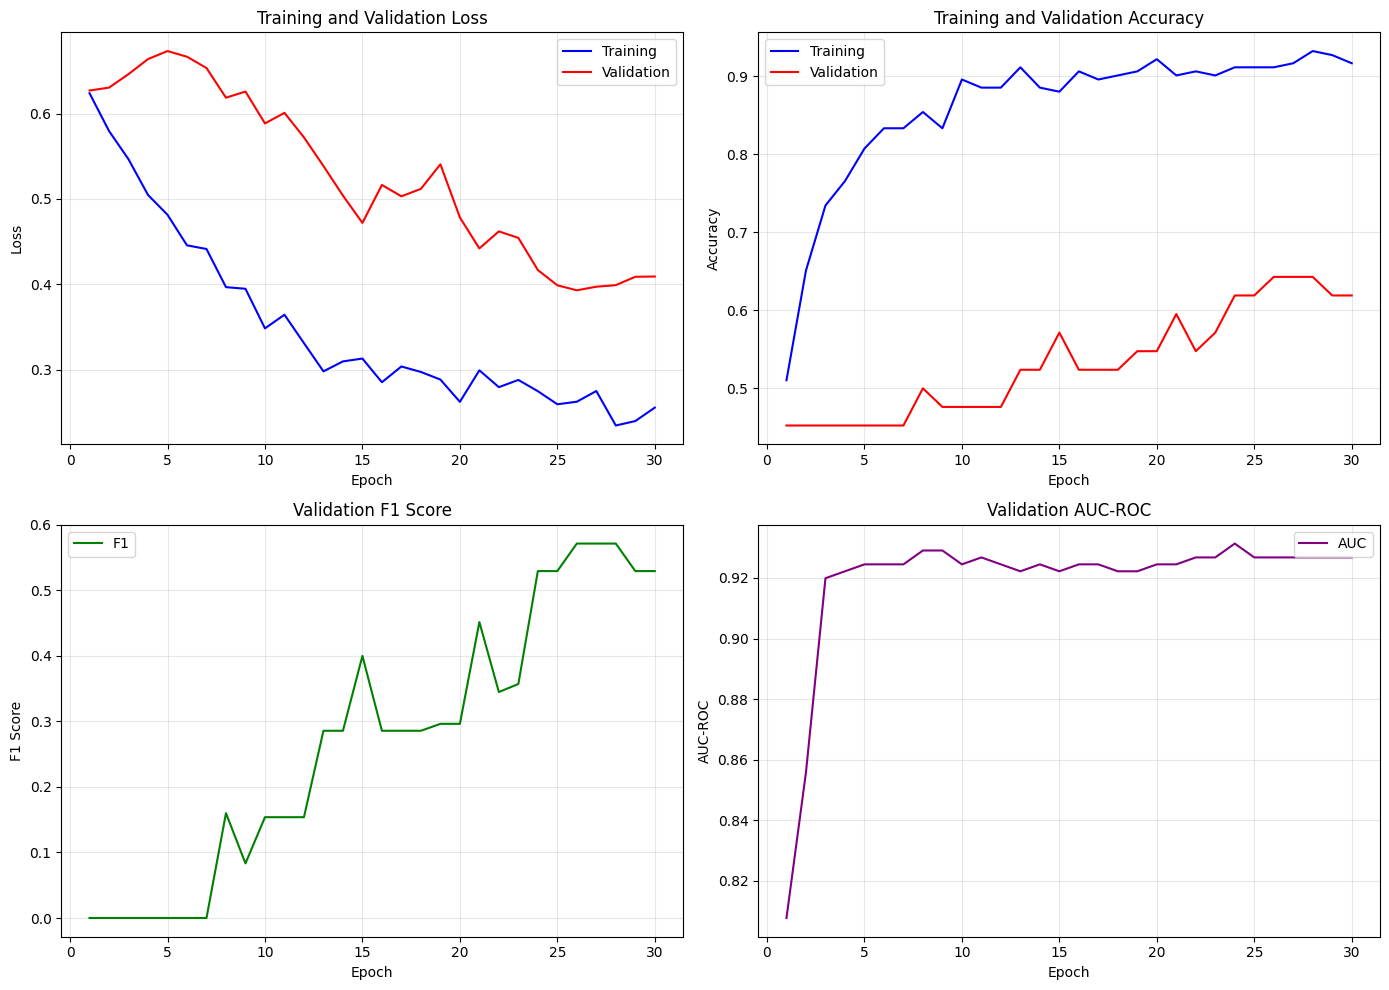

Best : checkpoints/best_model.pth
Training curve: outputs/training_curves.png


In [57]:

model = CustomAttendanceCNN(
    num_classes=1,
    dropout_conv=DROPOUT_CONV,
    dropout_fc=DROPOUT_FC,
    use_bn=USE_BATCH_NORM
)
print(f"  Total parameters: {count_parameters(model):,}")
print(f"  Device: {DEVICE}")

# Create trainer
trainer = Trainer(
    model, train_loader, val_loader, test_loader,
    device=DEVICE,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    class_weights=class_weights
)

# Start training
history = trainer.train(
    num_epochs=NUM_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE if USE_EARLY_STOPPING else NUM_EPOCHS
)

# Plot results
trainer.plot_training_curves()

# Save history
with open(OUTPUT_DIR / 'training_history.json', 'w') as f:
    json.dump(history, f, indent=2)


print(f"Best : {CHECKPOINT_DIR / 'best_model.pth'}")
print(f"Training curve: {OUTPUT_DIR / 'training_curves.png'}")

In [ ]:
l Loss:.*F1: 0.0000


## STEP 6: Evaluation on Test Set

In [ ]:
# Load best model for evaluation
best_model = CustomAttendanceCNN().to(DEVICE)
checkpoint = torch.load(CHECKPOINT_DIR / 'best_model.pth', map_location=DEVICE)
best_model.load_state_dict(checkpoint['model_state_dict'])
best_model.eval()

# Evaluate on test set
all_probs_test = []
all_labels_test = []
correct_test = 0
total_test = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.float().unsqueeze(1).to(DEVICE)

        if (labels == -1).any():
            continue

        outputs = best_model(images)
        probs = torch.sigmoid(outputs)
        predictions = (probs > 0.5).float()
        correct_test += (predictions == labels).sum().item()
        total_test += labels.size(0)

        all_probs_test.append(probs.cpu().numpy())
        all_labels_test.append(labels.cpu().numpy())

all_probs_test = np.concatenate(all_probs_test)
all_labels_test = np.concatenate(all_labels_test)

# Calculate metrics
test_acc = correct_test / total_test
test_preds = (all_probs_test > 0.5).astype(int)
test_precision = precision_score(all_labels_test, test_preds, zero_division=0)
test_recall = recall_score(all_labels_test, test_preds, zero_division=0)
test_f1 = f1_score(all_labels_test, test_preds, zero_division=0)
test_auc = roc_auc_score(all_labels_test, all_probs_test) if len(np.unique(all_labels_test)) > 1 else 0
test_cm = confusion_matrix(all_labels_test, test_preds)

# Display results
print("\n" + "="*70)
print("TEST SET EVALUATION")
print("="*70)
print(f"\n📊 Test Metrics:")
print(f"  Accuracy:  {test_acc:.4f}")
print(f"  Precision: {test_precision:.4f}")
print(f"  Recall:    {test_recall:.4f}")
print(f"  F1-Score:  {test_f1:.4f}")
print(f"  AUC-ROC:   {test_auc:.4f}")

print(f"\n🔍 Confusion Matrix:")
print(f"  {test_cm[0,0]:>4} {test_cm[0,1]:>4}  (Predicted)")
print(f"  {test_cm[1,0]:>4} {test_cm[1,1]:>4}")
print(f"  TN    FP")
print(f"  FN    TP")

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(test_cm, interpolation='nearest', cmap='Blues')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title('Confusion Matrix - Test Set')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Non-Spoof', 'Spoof'])
ax.set_yticklabels(['Non-Spoof', 'Spoof'])

# Add values to cells
for i in range(2):
    for j in range(2):
        text = ax.text(j, i, test_cm[i, j],
                       ha="center", va="center", color="w", fontsize=16, weight='bold')

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# ROC Curve
fig, ax = plt.subplots(figsize=(8, 6))
fpr, tpr, _ = roc_curve(all_labels_test, all_probs_test)
ax.plot(fpr, tpr, 'b-', linewidth=2, label=f'ROC Curve (AUC={test_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Test Set')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Confusion matrix saved: {OUTPUT_DIR / 'confusion_matrix.png'}")
print(f"✓ ROC curve saved: {OUTPUT_DIR / 'roc_curve.png'}")

## STEP 7: Inference on New Images

In [ ]:
class SpoofDetector:
    """Inference pipeline for spoof detection"""

    def __init__(self, model_path, device=DEVICE, threshold=PREDICTION_THRESHOLD):
        self.device = device
        self.threshold = threshold

        # Load model
        self.model = CustomAttendanceCNN()
        checkpoint = torch.load(model_path, map_location=device)
        self.model.load_state_dict(checkpoint['model_state_dict'])
        self.model.to(device)
        self.model.eval()

        print(f"✓ Model loaded from: {model_path}")

    def predict_image(self, image_path):
        """Predict on single image"""
        try:
            # Load and preprocess
            image = cv2.imread(image_path)
            if image is None:
                return None, None, f"Error: Could not read image"

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))

            # Prepare tensor
            image_tensor = torch.from_numpy(image).float().permute(2, 0, 1) / 255.0
            image_tensor = image_tensor.unsqueeze(0).to(self.device)

            # Normalize
            mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(self.device)
            std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(self.device)
            image_tensor = (image_tensor - mean) / std

            # Predict
            with torch.no_grad():
                logit = self.model(image_tensor)
                probability = torch.sigmoid(logit).item()

            # Classify
            if probability > self.threshold:
                prediction = 'SPOOF'
            else:
                prediction = 'NON-SPOOF'

            return prediction, probability, None

        except Exception as e:
            return None, None, str(e)

    def predict_batch(self, image_dir):
        """Predict on all images in directory"""
        results = []
        image_files = []

        # Find all image files
        for ext in ['*.jpg', '*.jpeg', '*.png', '*.bmp']:
            image_files.extend(Path(image_dir).glob(f"**/{ext}"))
            image_files.extend(Path(image_dir).glob(f"**/{ext.upper()}"))

        print(f"Found {len(image_files)} images to process")

        for idx, image_path in enumerate(image_files, 1):
            pred, prob, error = self.predict_image(str(image_path))

            results.append({
                'filename': image_path.name,
                'filepath': str(image_path),
                'prediction': pred if error is None else 'ERROR',
                'probability': prob if error is None else None,
                'error': error
            })

            if idx % 100 == 0:
                print(f"Processed {idx}/{len(image_files)}")

        df = pd.DataFrame(results)
        df.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)
        print(f"\n✓ Results saved to: {OUTPUT_DIR / 'predictions.csv'}")

        return df


# Create detector
detector = SpoofDetector(CHECKPOINT_DIR / 'best_model.pth')
print(f"  Threshold: {PREDICTION_THRESHOLD}")

### Predict on Single Image (Example)

In [ ]:
# Example: Predict on a single image
# Change the image path to your test image

test_image_path = test_paths[0]  # Use first test image as example

print(f"\nPredicting on: {test_image_path}")
pred, prob, error = detector.predict_image(test_image_path)

if error:
    print(f"Error: {error}")
else:
    print(f"Prediction:  {pred}")
    print(f"Probability: {prob:.4f}")
    print(f"Confidence:  {max(prob, 1-prob)*100:.1f}%")

### Predict on Batch (Folder)

In [ ]:
# Predict on entire folder
# Change this to your folder with test images

test_folder = '/content/dataset/spoof'  # Change to your test folder

if os.path.exists(test_folder):
    print(f"\nBatch predicting on folder: {test_folder}")
    results_df = detector.predict_batch(test_folder)

    # Summary
    print(f"\nPrediction Summary:")
    print(results_df['prediction'].value_counts())

    # Show first few results
    print(f"\nFirst 10 predictions:")
    print(results_df.head(10))
else:
    print(f"Folder not found: {test_folder}")